# Lab 8 – Edge Detection

the solution of the tasks and the extra experiments are in the bottom

Ali Jafar Altaweel

2240006456

7MA2

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# imgFile = 'kid1.jpg'
imgFile = './images/zebra.jpg'   # the kids photo is replaced with a new image

## 1. Sobel edge detector

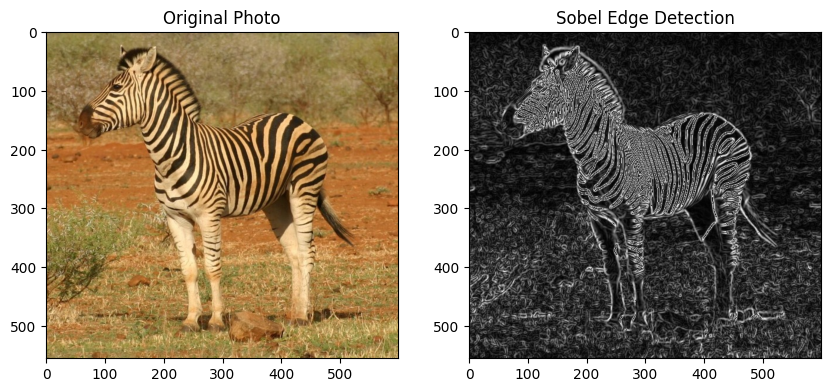

In [2]:
# 1. Load the real image

img = cv2.imread(imgFile)

# 2. Convert to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. Apply Gaussian Blur to reduce noise
# (5, 5) is the kernel size; 0 means standard deviation is calculated from kernel size

# ---------| You can try Sobel with Original Image, Gray scale and Blur
# ---------| Try these
# ---(1)---|  blurred = img
# ---(2)---|  blurred = gray

blurred = cv2.GaussianBlur(gray, (5, 5), 0) # blurred = img or gray   ## Check the results

# 4. Apply Sobel filter
# cv2.CV_64F handles the high precision needed for derivatives
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# 5. Calculate Magnitude (Final Edge Map)
sobel_combined = cv2.magnitude(sobelx, sobely)

# 6. Normalize to 0-255 for display
sobel_final = np.uint8(np.absolute(sobel_combined))

# Visualization
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo')
plt.subplot(1, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection')
plt.show()

## 2. Roberts edge detector

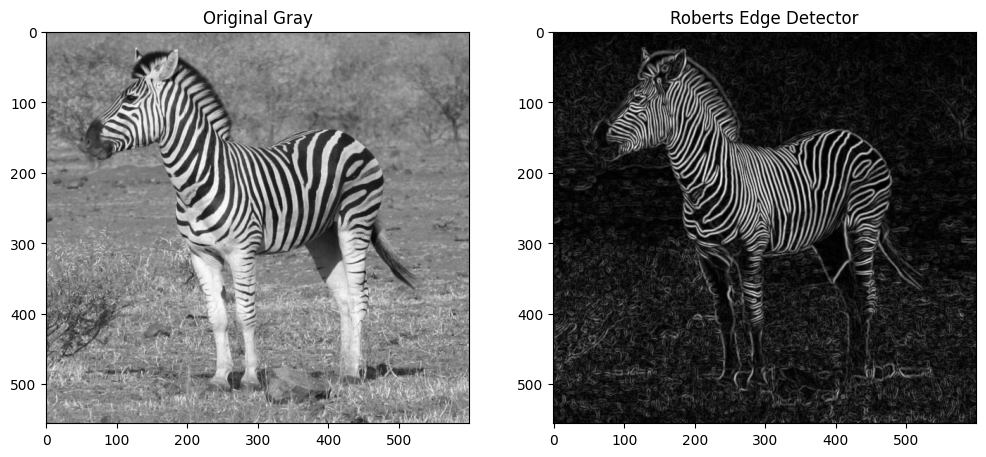

In [3]:
# Roberts compared to Sobel
#   Kernel size      : Roberts 2x2               | Sobel 3x3
#   Speed            : Roberts faster            | Sobel slower
#   Noise resistance : Roberts poor (sensitive)  | Sobel good (built-in smoothing)
#   Edge width       : Roberts very thin/sharp   | Sobel thicker

# 1. Load a real image in grayscale
image = cv2.imread(imgFile, 0) #cv2.IMREAD_GRAYSCALE)

# 2. Pre-process: Always blur for Roberts!
# Its 2x2 kernel is very sensitive to noise.
blurred = cv2.GaussianBlur(image, (5, 5), 0)

# 3. Define Roberts Cross kernels
kernel_x = np.array([[1, 0], [0, -1]], dtype=np.float64)
kernel_y = np.array([[0, 1], [-1, 0]], dtype=np.float64)

# 4. Apply kernels using convolution
roberts_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
roberts_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# 5. Calculate Magnitude (Combine X and Y)
# Magnitude = sqrt(Gx^2 + Gy^2)
roberts_combined = cv2.magnitude(roberts_x, roberts_y)

# 6. Convert to uint8 for display
roberts_final = np.uint8(np.absolute(roberts_combined))

# Display
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(image, cmap='gray'), plt.title('Original Gray')
plt.subplot(1, 2, 2), plt.imshow(roberts_final, cmap='gray'), plt.title('Roberts Edge Detector')
plt.show()

## 3. Prewitt edge detector

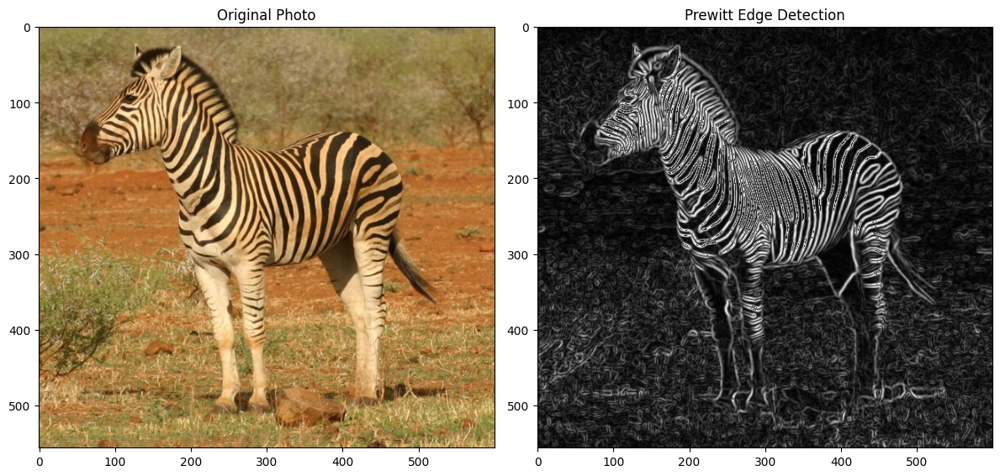

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load a real image in grayscale
img = cv2.imread(imgFile)

# 2. Grayscale & Blur (Essential for real photos to reduce grain)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

# 4. Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# 5. Calculate Magnitude (Combine X and Y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)

# 6. Normalize to 8-bit for display
prewitt_final = np.uint8(np.absolute(prewitt_combined))

# Visualizing results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo')
plt.subplot(1, 2, 2), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection')
plt.tight_layout()
plt.show()

## 4. Canny edge detector

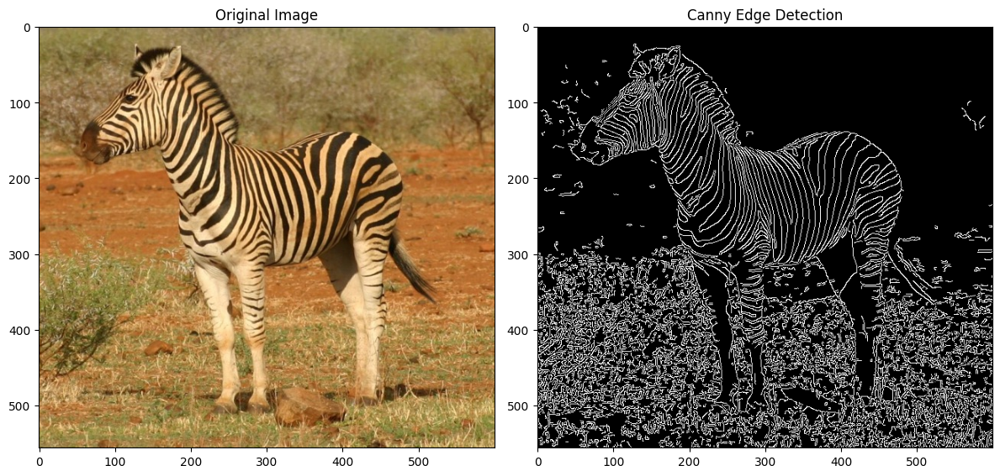

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the real image
# Replace 'building.jpg' with your file path
img = cv2.imread(imgFile)


# 2. Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. Apply Canny Edge Detection
# Syntax: cv2.Canny(image, low_threshold, high_threshold)
# Tip: A 1:2 or 1:3 ratio for thresholds usually works best
canny_edges = cv2.Canny(gray, 100, 200)

# 4. Visualization
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image')
plt.subplot(1, 2, 2), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection')
plt.tight_layout()
plt.show()

## 5. Multi-channel Canny edge detector

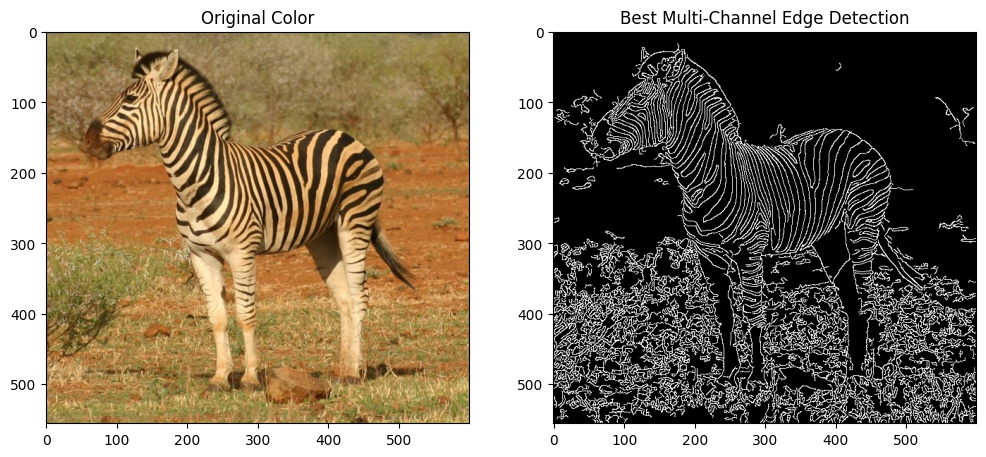

In [6]:
def best_color_edge_detector(image_path):
    # 1. Load the color image
    img = cv2.imread(image_path)
    if img is None:
        return "Image not found."

    # 2. Split into B, G, R channels
    channels = cv2.split(img)
    edge_maps = []

    for channel in channels:
        # 3. Pre-process each channel with Gaussian Blur to reduce noise
        blurred = cv2.GaussianBlur(channel, (5, 5), 0)

        # 4. Apply Canny to each channel
        # 50 and 150 are the low and high thresholds
        edges = cv2.Canny(blurred, 50, 150)
        edge_maps.append(edges)

    # 5. Merge edges from all channels using bitwise OR
    # This keeps any edge found in ANY of the three color layers
    combined_edges = cv2.bitwise_or(edge_maps[0], edge_maps[1])
    combined_edges = cv2.bitwise_or(combined_edges, edge_maps[2])

    return img, combined_edges

# Run the detector
original, edges = best_color_edge_detector(imgFile)

# Display results
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB)), plt.title('Original Color')
plt.subplot(1, 2, 2), plt.imshow(edges, cmap='gray'), plt.title('Best Multi-Channel Edge Detection')
plt.show()

## 6. LoG filter

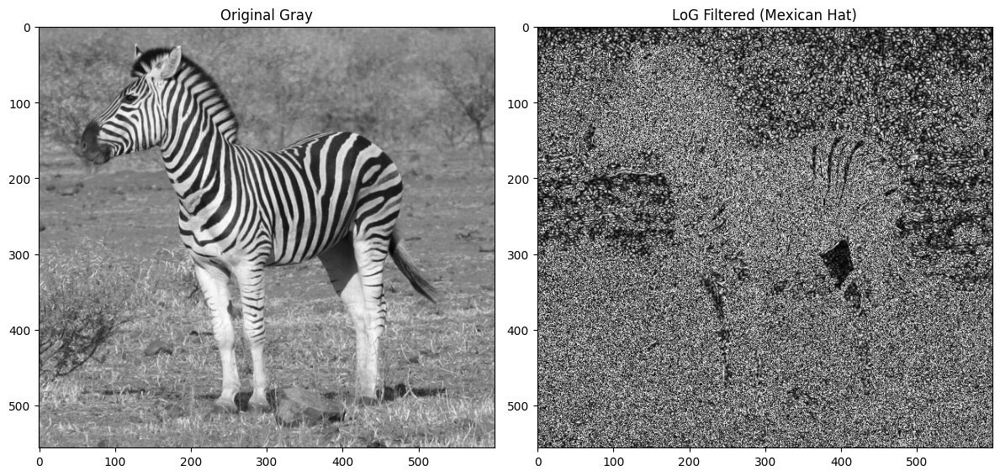

In [7]:
# 1. Load a real-world photo in grayscale
img = cv2.imread(imgFile, cv2.IMREAD_GRAYSCALE)

# 2. Step 1: Gaussian Blur (Smoothing)
# Larger kernel/sigma reduces more noise but may miss small edges
blurred = cv2.GaussianBlur(img, (5, 5), 0)

# 3. Step 2: Laplacian Operator (Second Derivative)
# cv2.CV_64F is used to store negative values (crucial for zero-crossings)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=5)

# 4. Post-processing: Normalize for display
# Since the Laplacian has negative and positive values, we take the absolute value
log_final = np.uint8(np.absolute(laplacian))

# Visualization
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original Gray')
plt.subplot(1, 2, 2), plt.imshow(log_final, cmap='gray'), plt.title('LoG Filtered (Mexican Hat)')
plt.tight_layout()
plt.show()

## 7. DoG filter

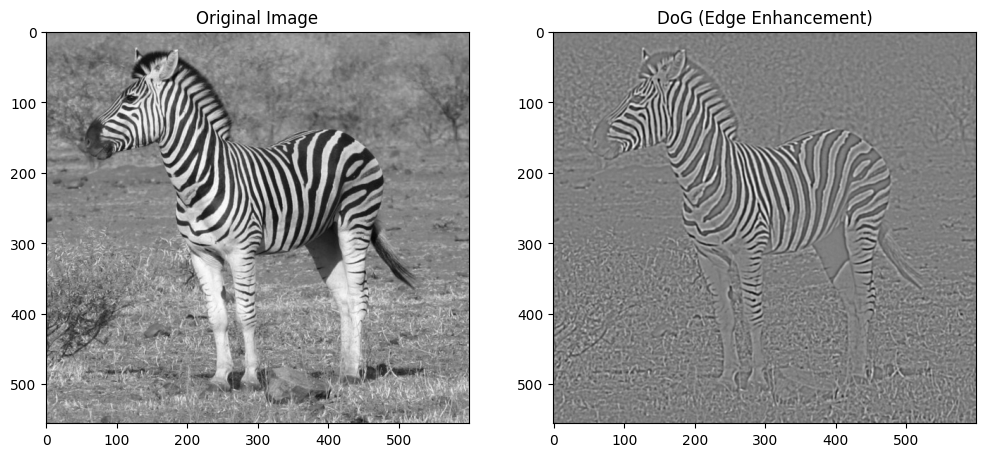

In [8]:
# 1. Load the real-world photo
img = cv2.imread(imgFile, cv2.IMREAD_GRAYSCALE)

# 2. Apply two Gaussian blurs with different standard deviations (Sigmas)
# Low sigma preserves detail; High sigma captures broad structure
blur_narrow = cv2.GaussianBlur(img, (0, 0), sigmaX=1.0)
blur_wide = cv2.GaussianBlur(img, (0, 0), sigmaX=2.0)

# 3. Calculate the Difference (DoG)
# Note: We use float32 to avoid overflow/underflow during subtraction
dog = blur_narrow.astype(np.float32) - blur_wide.astype(np.float32)

# 4. Normalize or Threshold for visibility
# Option A: Map to 0-255 range
dog_normalized = cv2.normalize(dog, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Option B: Simple threshold to create a binary edge map
_, dog_binary = cv2.threshold(dog_normalized, 127, 255, cv2.THRESH_BINARY)

# Visualization
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(1, 2, 2), plt.imshow(dog_normalized, cmap='gray'), plt.title('DoG (Edge Enhancement)')
plt.show()

## 8. Gradient edge detector for colored images

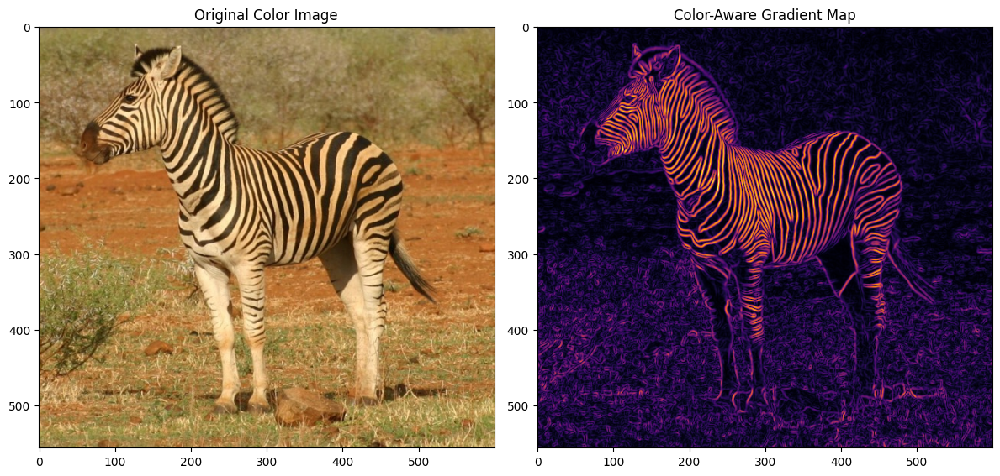

In [9]:
# 1. Load the real-world color image
image = cv2.imread(imgFile)

# 2. Split the image into its R, G, and B components
# Note: OpenCV uses BGR order by default
b, g, r = cv2.split(image)

def get_channel_gradient(channel):
    # Use Sobel for gradient calculation on a single channel
    # Blur first to reduce noise in that specific color layer
    blurred = cv2.GaussianBlur(channel, (3, 3), 0)
    gx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
    return cv2.magnitude(gx, gy)

# 3. Compute gradients for each color channel
grad_b = get_channel_gradient(b)
grad_g = get_channel_gradient(g)
grad_r = get_channel_gradient(r)

# 4. Combine gradients from all channels
# This ensures edges from color-only transitions are captured
combined_gradient = np.sqrt(grad_b**2 + grad_g**2 + grad_r**2)

# 5. Normalize to 0-255 for visualization
color_edges = cv2.normalize(combined_gradient, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Visualization
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)), plt.title('Original Color Image')
plt.subplot(1, 2, 2), plt.imshow(color_edges, cmap='inferno'), plt.title('Color-Aware Gradient Map')
plt.tight_layout()
plt.show()

## 9. Student tasks

### Task 1 – Apply Edge Detection Methods

Select a new image of your choice. Do not use the image provided in the original notebook.

Apply the following methods to your selected image using the provided notebook as a reference:

- Sobel Edge Detector
- Prewitt Edge Detector
- Canny Edge Detector

Display the original image and the three resulting edge maps.

### Task 2 – Investigate the Effect of Canny Thresholds

Apply Canny edge detection using the following threshold pairs:

- Low = 30, High = 90
- Low = 50, High = 150
- Low = 100, High = 200

Display the three resulting edge maps side by side.

Explain how changing the thresholds affects the number of detected edges and the visibility of image details.

### Task 1 Solution – Sobel, Prewitt and Canny on a new image (zebra)

image: (556, 600, 3) uint8
Sobel max magnitude  : 464.2
Prewitt max magnitude: 347.1
Canny edge pixels    : 50267


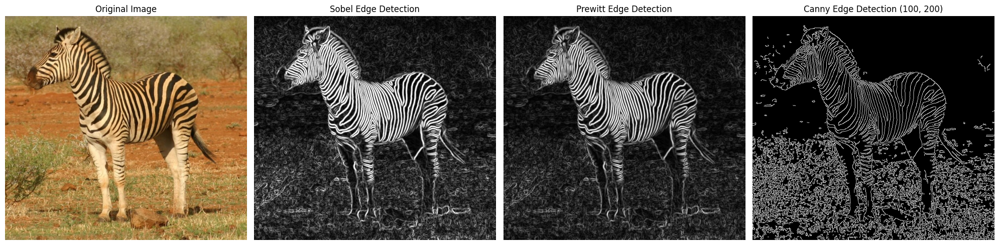

In [10]:
# new image that is not used anywhere in the labs: a zebra photo from Wikimedia Commons
# "Zebra standing alone crop.jpg" (CC BY-SA 3.0), resized to 600 px wide
taskFile = './images/zebra.jpg'

# 1. Load the image, convert to grayscale and blur (same steps as the notebook)
task_img = cv2.imread(taskFile)
task_gray = cv2.cvtColor(task_img, cv2.COLOR_BGR2GRAY)
task_blur = cv2.GaussianBlur(task_gray, (5, 5), 0)
print("image:", task_img.shape, task_img.dtype)

# 2. Sobel (cv2.Sobel with ksize=3, combined with the magnitude)
t_sobelx = cv2.Sobel(task_blur, cv2.CV_64F, 1, 0, ksize=3)
t_sobely = cv2.Sobel(task_blur, cv2.CV_64F, 0, 1, ksize=3)
t_sobel = cv2.magnitude(t_sobelx, t_sobely)

# 3. Prewitt (manual kernels with cv2.filter2D)
prewitt_kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
prewitt_ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
t_prewitt = cv2.magnitude(cv2.filter2D(task_blur, cv2.CV_64F, prewitt_kx),
                          cv2.filter2D(task_blur, cv2.CV_64F, prewitt_ky))

# 4. Canny (same thresholds as the notebook)
t_canny = cv2.Canny(task_gray, 100, 200)

# 5. Convert to 8-bit for display, clipping so values above 255 do not wrap around
t_sobel_8 = np.clip(t_sobel, 0, 255).astype(np.uint8)
t_prewitt_8 = np.clip(t_prewitt, 0, 255).astype(np.uint8)
print("Sobel max magnitude  :", round(t_sobel.max(), 1))
print("Prewitt max magnitude:", round(t_prewitt.max(), 1))
print("Canny edge pixels    :", (t_canny > 0).sum())

# Display the original image and the three edge maps
plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1), plt.imshow(cv2.cvtColor(task_img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(1, 4, 2), plt.imshow(t_sobel_8, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.subplot(1, 4, 3), plt.imshow(t_prewitt_8, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.subplot(1, 4, 4), plt.imshow(t_canny, cmap='gray'), plt.title('Canny Edge Detection (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.show()

Explanation: I used a zebra photo from Wikimedia Commons, which is not used anywhere in the labs. Sobel and Prewitt give almost the same gradient map: every black and white stripe becomes a thick bright edge, and the grass and the bushes give a weaker gray texture. Prewitt is a little darker (maximum 347 against 464 for Sobel) because its kernels have no weight of 2 in the middle row. Canny is different because it gives a binary map with thin 1-pixel lines, so every stripe and the outline of the zebra are sharp lines, and it found 50,267 edge pixels, most of them on the stripes and the grass.

### Task 2 Solution – Effect of the Canny thresholds

Low = 30  High = 90  -> edge pixels:  93085 (27.90% of the image)
Low = 50  High = 150 -> edge pixels:  70541 (21.15% of the image)
Low = 100 High = 200 -> edge pixels:  50267 (15.07% of the image)


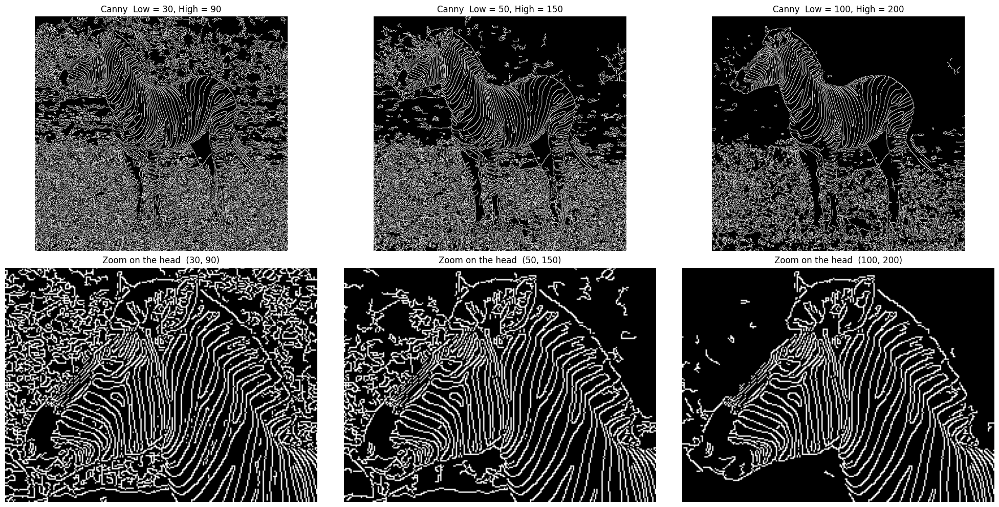

In [11]:
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_maps = {}

for low, high in threshold_pairs:
    edges_t = cv2.Canny(task_gray, low, high)
    canny_maps[(low, high)] = edges_t
    n = (edges_t > 0).sum()
    print(f"Low = {low:<3} High = {high:<3} -> edge pixels: {n:6d} ({n / edges_t.size * 100:5.2f}% of the image)")

# the three edge maps side by side (top) and a zoom on the head (bottom) to compare the details
head = (slice(20, 200), slice(40, 280))
fig, ax = plt.subplots(2, 3, figsize=(20, 10))
for j, ((low, high), e) in enumerate(canny_maps.items()):
    ax[0, j].imshow(e, cmap='gray'), ax[0, j].set_title(f'Canny  Low = {low}, High = {high}')
    ax[1, j].imshow(e[head], cmap='gray'), ax[1, j].set_title(f'Zoom on the head  ({low}, {high})')
for a in ax.ravel(): a.axis('off')
plt.tight_layout()
plt.show()

Explanation: Canny keeps every pixel whose gradient is above the high threshold as a strong edge, drops every pixel below the low threshold, and keeps the pixels in between only if they are connected to a strong edge. So when the thresholds go up, fewer pixels pass and the number of edges drops: 93,085 edge pixels (27.9% of the image) with (30, 90), 70,541 (21.2%) with (50, 150) and 50,267 (15.1%) with (100, 200). With low thresholds the weak edges of the bushes and the soil also become edges, so the image is full of detail but the zebra is mixed with the background, and in the zoom its muzzle is lost in the bushes. With (100, 200) the bushes behind the zebra almost disappear and the stripes, the ears and the outline of the head stay clear, because they have a very strong contrast. The grass in the front still gives many edges even at (100, 200), because the dry grass blades also have a strong contrast.

## 10. Extra experiments

### Experiment 1 – Sobel on the original, gray and blurred image

blurred = img                  output shape (556, 600, 3)   max  807.0   pixels with magnitude > 100: 31.83%
blurred = gray                 output shape (556, 600)      max  791.1   pixels with magnitude > 100: 27.85%
blurred = GaussianBlur(gray)   output shape (556, 600)      max  464.2   pixels with magnitude > 100: 15.69%


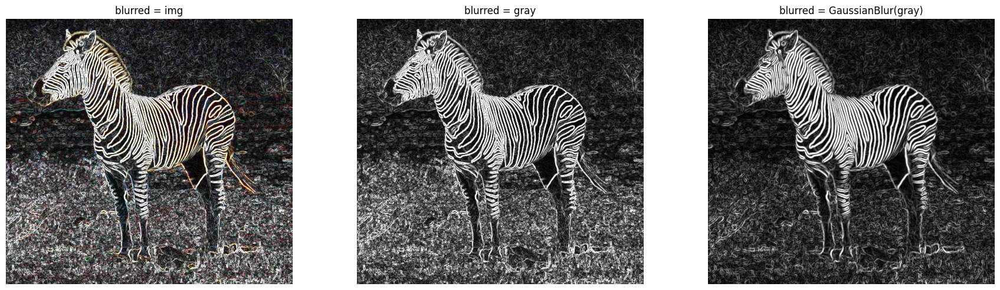

In [12]:
# the Sobel cell says: "You can try Sobel with Original Image, Gray scale and Blur"
img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
sources = {"blurred = img": img,
           "blurred = gray": gray,
           "blurred = GaussianBlur(gray)": cv2.GaussianBlur(gray, (5, 5), 0)}

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (name, src) in zip(ax, sources.items()):
    sx = cv2.Sobel(src, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(src, cv2.CV_64F, 0, 1, ksize=3)
    mag = cv2.magnitude(sx, sy)
    strength = mag.max(axis=2) if mag.ndim == 3 else mag      # strongest channel for the colour image
    print(f"{name:<30} output shape {str(mag.shape):<15} max {mag.max():6.1f}   "
          f"pixels with magnitude > 100: {(strength > 100).mean() * 100:5.2f}%")
    disp = np.clip(mag, 0, 255).astype(np.uint8)              # clipped, see Experiment 2
    a.imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB) if disp.ndim == 3 else disp, cmap='gray')
    a.set_title(name); a.axis('off')
plt.tight_layout()
plt.show()

Explanation: on the colour image Sobel works on each of the B, G and R channels separately, so the result is a colour edge map where every edge takes the colour of the channel that changes the most, for example the orange edge along the back of the zebra. The gray and colour versions both pick up the texture of the grass and the bushes as edges (31.8% and 27.9% of the pixels are above 100), and blurring first halves that to 15.7% and keeps mainly the stripes and the outline of the zebra, with a much lower maximum magnitude.

### Experiment 2 – Fixing the uint8 wrap-around in the edge maps

np.uint8 of [255, 256, 300, 600] -> [255   0  44  88]

Sobel    max |value| =   464.2   pixels above 255:  14989 ( 4.49%)
Roberts  max |value| =    87.0   pixels above 255:      0 ( 0.00%)
Prewitt  max |value| =   347.1   pixels above 255:   4565 ( 1.37%)
LoG      max |value| =  2722.0   pixels above 255: 122199 (36.63%)

convertScaleAbs gives the same LoG result: True


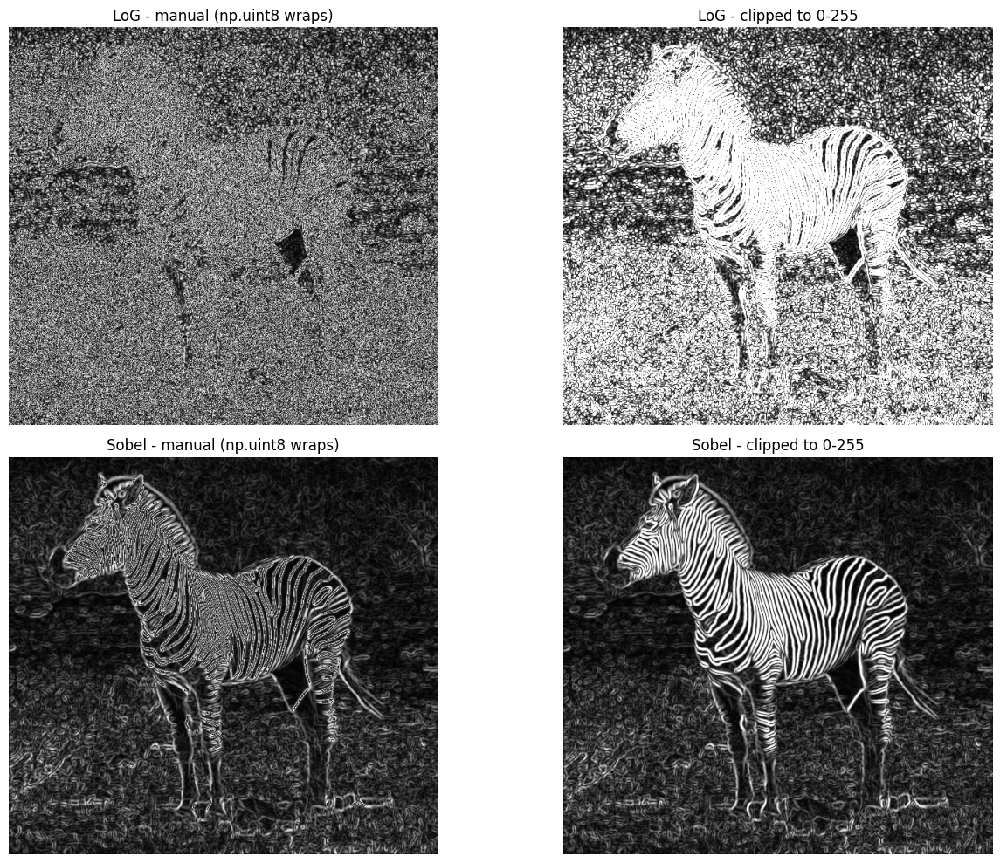

In [13]:
# the manual converts the magnitudes with np.uint8(np.absolute(...)), which does not clip:
print("np.uint8 of [255, 256, 300, 600] ->", np.uint8(np.array([255.0, 256.0, 300.0, 600.0])))
print()

maps = {"Sobel": sobel_combined, "Roberts": roberts_combined,
        "Prewitt": prewitt_combined, "LoG": laplacian}
for name, m in maps.items():
    over = np.abs(m) > 255
    print(f"{name:<8} max |value| = {np.abs(m).max():7.1f}   pixels above 255: {over.sum():6d} ({over.mean() * 100:5.2f}%)")

# fix: clip to 0-255 before the cast (cv2.convertScaleAbs does the same)
log_fixed = np.clip(np.absolute(laplacian), 0, 255).astype(np.uint8)
sobel_fixed = np.clip(sobel_combined, 0, 255).astype(np.uint8)
print("\nconvertScaleAbs gives the same LoG result:", np.array_equal(log_fixed, cv2.convertScaleAbs(laplacian)))

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].imshow(log_final, cmap='gray'), ax[0, 0].set_title('LoG - manual (np.uint8 wraps)')
ax[0, 1].imshow(log_fixed, cmap='gray'), ax[0, 1].set_title('LoG - clipped to 0-255')
ax[1, 0].imshow(sobel_final, cmap='gray'), ax[1, 0].set_title('Sobel - manual (np.uint8 wraps)')
ax[1, 1].imshow(sobel_fixed, cmap='gray'), ax[1, 1].set_title('Sobel - clipped to 0-255')
for a in ax.ravel(): a.axis('off')
plt.tight_layout()
plt.show()

Explanation: np.uint8 keeps only the value modulo 256, so a strong edge of 300 becomes 44 and turns dark. On the zebra the LoG with ksize=5 reaches 2722, so 36.6% of its pixels wrap around and the manual result looks like random noise where the zebra almost disappears. Sobel also wraps on 4.5% of the pixels, which shows up as dark lines in the middle of the white stripe edges, and Prewitt on 1.4%. Clipping before the cast keeps every strong edge white. Roberts never goes above 255 here, so its result is not affected.

### Experiment 3 – Checking the Roberts vs Sobel comparison

operator   edge width (px)   edge / noise ratio  time on zebra (ms)


Roberts                  1                 9.56                5.73


Prewitt                  2                12.26                7.50


Sobel                    2                11.60                6.36


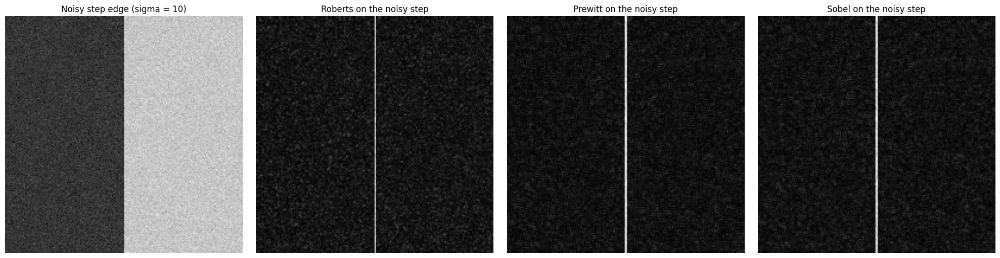

In [14]:
import timeit

# synthetic vertical step edge: 60 on the left, 180 on the right, and a noisy copy
step = np.full((200, 200), 60, np.uint8)
step[:, 100:] = 180
noisy_step = np.clip(step + np.random.default_rng(0).normal(0, 10, step.shape), 0, 255).astype(np.uint8)

kernels = {
    "Roberts": (np.array([[1, 0], [0, -1]], np.float64), np.array([[0, 1], [-1, 0]], np.float64)),
    "Prewitt": (np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float64),
                np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float64)),
    "Sobel":   (np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float64),
                np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float64)),
}

def gradient(im, k):
    return cv2.magnitude(cv2.filter2D(im, cv2.CV_64F, k[0]), cv2.filter2D(im, cv2.CV_64F, k[1]))

main_gray = cv2.imread(imgFile, 0)
print(f"{'operator':<9}{'edge width (px)':>17}{'edge / noise ratio':>21}{'time on zebra (ms)':>20}")
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(noisy_step, cmap='gray'), ax[0].set_title('Noisy step edge (sigma = 10)'), ax[0].axis('off')
for a, (name, k) in zip(ax[1:], kernels.items()):
    profile = gradient(step, k)[100]                         # one row across the clean edge
    width = (profile > 0.5 * profile.max()).sum()            # pixels above half of the peak
    g = gradient(noisy_step, k)
    ratio = g[:, 97:104].max(axis=1).mean() / g[:, 20:80].mean()   # edge response / response in the flat area
    ms = timeit.timeit(lambda: gradient(main_gray, k), number=200) / 200 * 1000
    print(f"{name:<9}{width:>17}{ratio:>21.2f}{ms:>20.2f}")
    a.imshow(g, cmap='gray'), a.set_title(f'{name} on the noisy step'), a.axis('off')
plt.tight_layout()
plt.show()

Explanation: the numbers agree with the comparison in the manual. Roberts gives a 1-pixel edge while Prewitt and Sobel give a 2-pixel edge, Roberts is the fastest because its kernel has only 4 weights, and it has the lowest edge-to-noise ratio, so it is the most sensitive to noise. Prewitt came out slightly above Sobel on this Gaussian noise because it averages the 3 rows with equal weights.

### Experiment 4 – Canny thresholds and blurring

Canny(50, 150) no blur   edge pixels: 21.14%
Canny(50, 150) 5x5 blur  edge pixels: 11.10%
Canny(100, 200) no blur   edge pixels: 15.07%
Canny(100, 200) 5x5 blur  edge pixels:  5.61%
Canny(150, 300) no blur   edge pixels:  8.88%
Canny(150, 300) 5x5 blur  edge pixels:  3.76%


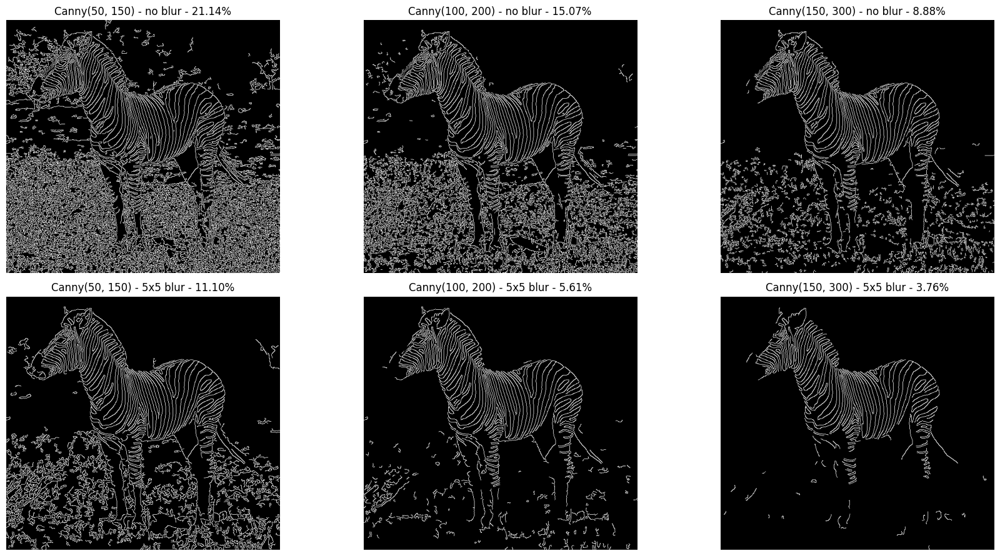

In [15]:
main_gray = cv2.imread(imgFile, 0)
main_blur = cv2.GaussianBlur(main_gray, (5, 5), 0)
thresholds = [(50, 150), (100, 200), (150, 300)]

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for j, (lo, hi) in enumerate(thresholds):
    for i, (name, src) in enumerate([("no blur", main_gray), ("5x5 blur", main_blur)]):
        e = cv2.Canny(src, lo, hi)
        pct = (e > 0).mean() * 100
        print(f"Canny({lo}, {hi}) {name:<9} edge pixels: {pct:5.2f}%")
        ax[i, j].imshow(e, cmap='gray'), ax[i, j].set_title(f'Canny({lo}, {hi}) - {name} - {pct:.2f}%')
        ax[i, j].axis('off')
plt.tight_layout()
plt.show()

Explanation: raising the thresholds keeps only the strongest edges, and blurring first removes the small texture edges of the grass and the bushes. Canny(100, 200) on the raw gray image, as in the manual, still marks 15.1% of the pixels, most of them in the grass, while the same thresholds after a 5x5 blur drop to 5.6% and give mostly the stripes and the outline of the zebra.

### Experiment 5 – Gray Canny vs multi-channel Canny on a colour image

edge pixels, gray Canny        : 23434
edge pixels, multi-channel     : 33084
found only in the colour layers: 10272


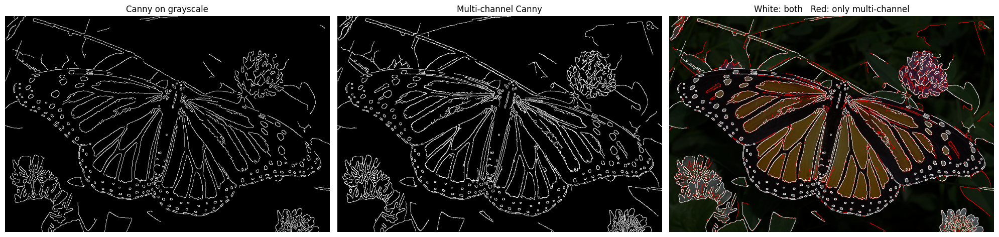


bird.png channels identical: True


In [16]:
bimg = cv2.imread("./images/Butterfly.jpg")
bgray = cv2.cvtColor(bimg, cv2.COLOR_BGR2GRAY)

gray_edges = cv2.Canny(cv2.GaussianBlur(bgray, (5, 5), 0), 50, 150)   # same blur and thresholds as section 5
_, color_edges_mc = best_color_edge_detector("./images/Butterfly.jpg")
only_color = (color_edges_mc > 0) & (gray_edges == 0)

print("edge pixels, gray Canny        :", (gray_edges > 0).sum())
print("edge pixels, multi-channel     :", (color_edges_mc > 0).sum())
print("found only in the colour layers:", only_color.sum())

overlay = cv2.cvtColor(bimg, cv2.COLOR_BGR2RGB) // 3
overlay[gray_edges > 0] = (255, 255, 255)
overlay[only_color] = (255, 0, 0)

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].imshow(gray_edges, cmap='gray'), ax[0].set_title('Canny on grayscale')
ax[1].imshow(color_edges_mc, cmap='gray'), ax[1].set_title('Multi-channel Canny')
ax[2].imshow(overlay), ax[2].set_title('White: both   Red: only multi-channel')
for a in ax: a.axis('off')
plt.tight_layout()
plt.show()

# the bird image looks gray: are its channels equal?
bird = cv2.imread("./images/bird.png")
print("\nbird.png channels identical:", np.array_equal(bird[..., 0], bird[..., 1]) and np.array_equal(bird[..., 1], bird[..., 2]))

Explanation: two colours can have almost the same gray level, for example the green leaves and the pink flower, so the edge between them disappears after the conversion to gray. Running Canny on each channel and joining the results with OR found 10,272 extra edge pixels on the butterfly (33,084 instead of 23,434), mostly around the pink flower, the leaves and the borders of the orange wing cells. The bird image is already gray in all three channels, so for it the two methods give the same result.

### Experiment 6 – All detectors on the other lab images

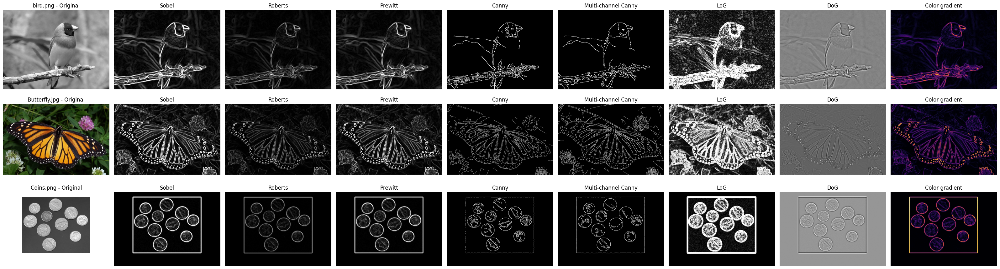

In [17]:
def run_all(path):
    im = cv2.imread(path)
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    b = cv2.GaussianBlur(g, (5, 5), 0)
    to8 = lambda m: np.clip(np.absolute(m), 0, 255).astype(np.uint8)
    out = {"Original": cv2.cvtColor(im, cv2.COLOR_BGR2RGB)}
    out["Sobel"] = to8(cv2.magnitude(cv2.Sobel(b, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(b, cv2.CV_64F, 0, 1, ksize=3)))
    out["Roberts"] = to8(gradient(b, kernels["Roberts"]))
    out["Prewitt"] = to8(gradient(b, kernels["Prewitt"]))
    out["Canny"] = cv2.Canny(g, 100, 200)
    out["Multi-channel Canny"] = best_color_edge_detector(path)[1]
    out["LoG"] = to8(cv2.Laplacian(b, cv2.CV_64F, ksize=5))
    d = cv2.GaussianBlur(g, (0, 0), 1.0).astype(np.float32) - cv2.GaussianBlur(g, (0, 0), 2.0).astype(np.float32)
    out["DoG"] = cv2.normalize(d, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    out["Color gradient"] = cv2.normalize(np.sqrt(sum(get_channel_gradient(c) ** 2 for c in cv2.split(im))),
                                          None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return out

files = ["bird.png", "Butterfly.jpg", "Coins.png"]
fig, ax = plt.subplots(len(files), 9, figsize=(32, 9))
for i, f in enumerate(files):
    for j, (name, res) in enumerate(run_all(f"./images/{f}").items()):
        ax[i, j].imshow(res, cmap='inferno' if name == "Color gradient" else 'gray')
        ax[i, j].set_title(f"{f} - {name}" if j == 0 else name)
        ax[i, j].axis('off')
plt.tight_layout()
plt.show()

Explanation: the main sections use zebra.jpg, so here every detector runs on the three other images that came with the lab (with the clipping fix). On the coins all detectors find the round outlines easily because of the strong contrast with the dark background, and they all also detect the white frame around the photo. Roberts gives the weakest response everywhere, Canny gives clean thin lines, the LoG with ksize=5 saturates on every textured area, and on the butterfly the colour gradient responds most strongly around the orange and white spots.

### Experiment 7 – LoG zero crossings and the DoG binary map

correlation between DoG(1, 2) and LoG(sigma 1.5): -0.972
DoG binary map (Option B) white pixels: 44.81 %


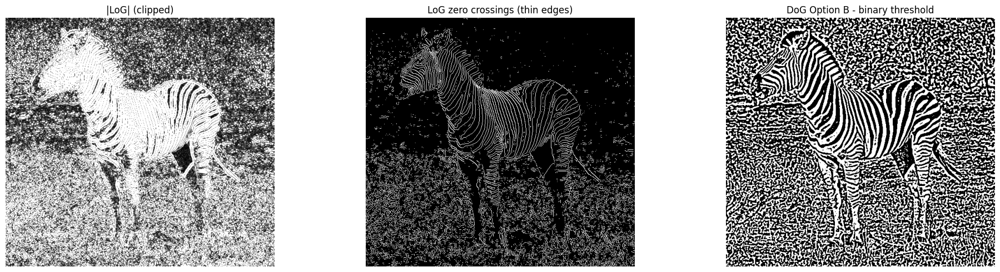

In [18]:
def zero_crossings(lap, thresh):
    # an edge is where the Laplacian changes sign between two neighbours with a big enough jump
    zc = np.zeros(lap.shape, np.uint8)
    for dy, dx in [(0, 1), (1, 0)]:
        a = lap[:lap.shape[0] - dy, :lap.shape[1] - dx]
        b = lap[dy:, dx:]
        zc[:lap.shape[0] - dy, :lap.shape[1] - dx][(a * b < 0) & (np.abs(a - b) > thresh)] = 255
    return zc

zc = zero_crossings(laplacian, 0.1 * np.abs(laplacian).max())

# DoG is an approximation of the (negative) LoG: compare them on the same image
img_g = cv2.imread(imgFile, cv2.IMREAD_GRAYSCALE)
log_15 = cv2.Laplacian(cv2.GaussianBlur(img_g, (0, 0), 1.5), cv2.CV_64F)
print("correlation between DoG(1, 2) and LoG(sigma 1.5):", round(np.corrcoef(dog.ravel(), log_15.ravel())[0, 1], 3))
print("DoG binary map (Option B) white pixels:", round((dog_binary > 0).mean() * 100, 2), "%")

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].imshow(log_fixed, cmap='gray'), ax[0].set_title('|LoG| (clipped)')
ax[1].imshow(zc, cmap='gray'), ax[1].set_title('LoG zero crossings (thin edges)')
ax[2].imshow(dog_binary, cmap='gray'), ax[2].set_title('DoG Option B - binary threshold')
for a in ax: a.axis('off')
plt.tight_layout()
plt.show()

Explanation: the manual says the negative values of the LoG are crucial for the zero crossings, but it only shows the absolute value, which saturates on the zebra and the grass. Marking the pixels where the LoG changes sign with a strong jump gives a single thin line on each side of every stripe. The DoG cell also computes the binary map of Option B without showing it. Since the normalized DoG is about 127 where the image is flat, the threshold at 127 splits the image into the bright and dark sides of each edge, so the stripes come out as a black and white pattern with 44.8% of the pixels white. The correlation of -0.97 with the LoG confirms that the DoG is an approximation of the negative LoG.

### Experiment 8 – Counting the coins with edge detection

coins found: 10
radii (px) : [23, 23, 24, 25, 28, 28, 28, 29, 30, 30]


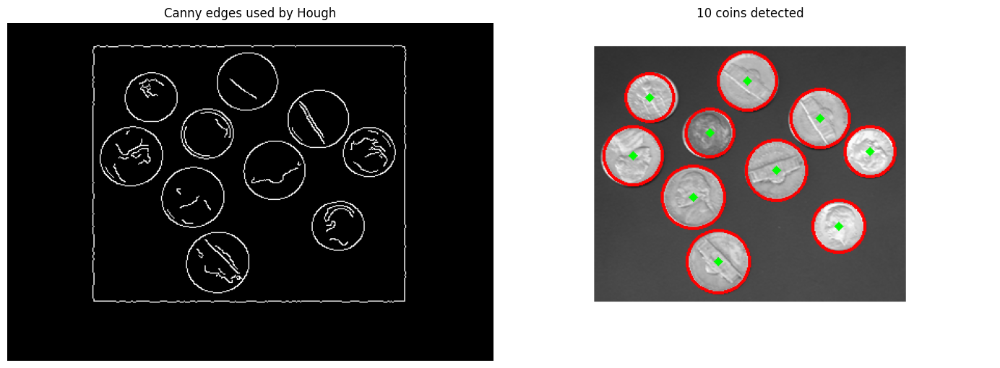

In [19]:
coins = cv2.imread("./images/Coins.png")
coins_gray = cv2.GaussianBlur(cv2.cvtColor(coins, cv2.COLOR_BGR2GRAY), (5, 5), 0)

# HoughCircles uses Canny inside (param1 = high threshold) and then votes for circle centres on the edges
circles = cv2.HoughCircles(coins_gray, cv2.HOUGH_GRADIENT, dp=1, minDist=30,
                           param1=150, param2=30, minRadius=15, maxRadius=40)
circles = np.round(circles[0]).astype(int)
print("coins found:", len(circles))
print("radii (px) :", sorted(circles[:, 2].tolist()))

result = cv2.cvtColor(coins, cv2.COLOR_BGR2RGB).copy()
for x, y, r in circles:
    cv2.circle(result, (x, y), r, (255, 0, 0), 2)
    cv2.circle(result, (x, y), 2, (0, 255, 0), 3)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(cv2.Canny(coins_gray, 75, 150), cmap='gray'), ax[0].set_title('Canny edges used by Hough')
ax[1].imshow(result), ax[1].set_title(f'{len(circles)} coins detected')
for a in ax: a.axis('off')
plt.tight_layout()
plt.show()

Explanation: the edges alone do not tell how many coins there are, because some outlines are broken, the coin faces have edges inside them and the white frame around the photo is also an edge. The Hough transform uses the Canny edges to vote for circle centres, and it found all 10 coins. The radii split into two groups, around 23-25 px for the small coins and 28-30 px for the big ones.